In [1]:
import shutil
from pathlib import Path

DATA_DIR = Path("../data")
SPLIT_DIR = Path("../data/preprocessing")

assignments = {
    "train": ["subset0", "subset1", "subset2"],
    "validation": ["subset3"],
    "test": ["subset4"],
}

for split_name, subset_names in assignments.items():
    destination = SPLIT_DIR / split_name
    destination.mkdir(parents=True, exist_ok=True)

    for subset_name in subset_names:
        source = DATA_DIR / subset_name
        target = destination / subset_name

        if not target.exists():
            shutil.copytree(source, target)

print("Finished copying subsets.")

Finished copying subsets.


In [2]:
%pip install -q \
    pillow \
    numpy \
    pandas \
    scipy \
    scikit-image \
    matplotlib \
    pydicom \
    SimpleITK

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
from glob import glob
import scipy.ndimage as ndi
import SimpleITK as sitk
from skimage import measure, morphology, segmentation, filters

In [10]:
def load_itk(filename):
    # Reads the image using SimpleITK
    itkimage = sitk.ReadImage(filename)

    # Convert the image to a  numpy array first and then shuffle the dimensions to get axis in the order z,y,x
    image_array = sitk.GetArrayFromImage(itkimage)

    # Read the origin of the ct_scan, will be used to convert the coordinates from world to voxel and vice versa.
    origin = np.array(list(reversed(itkimage.GetOrigin())))

    # Read the spacing along each dimension
    spacing = np.array(list(reversed(itkimage.GetSpacing())))

    return image_array, origin, spacing


def resample(image, previous_spacing, new_spacing=(1., 1., 1.)):
    previous_spacing = np.array(previous_spacing, dtype=np.float32)
    resize_factor = previous_spacing / new_spacing
    new_shape = np.round(image.shape * resize_factor)
    real_resize = new_shape / image.shape
    new_spacing = previous_spacing / real_resize

    image = ndi.zoom(image, real_resize, mode='nearest')
    return image, new_spacing

In [11]:
def get_segmented_lungs(im):
    binary = im < -604
    cleared = segmentation.clear_border(binary)
    label_img = measure.label(cleared)

    areas = [r.area for r in measure.regionprops(label_img)]
    if len(areas) >= 2:
        areas.sort()
        for region in measure.regionprops(label_img):
            if region.area < areas[-2]:
                for c in region.coords:
                    label_img[c[0], c[1]] = 0

    r = label_img == 1
    l = label_img == 2
    r = ndi.binary_fill_holes(filters.roberts(r))
    l = ndi.binary_fill_holes(filters.roberts(l))

    mask = morphology.convex_hull_image(r) | morphology.convex_hull_image(l)
    mask = morphology.binary_closing(mask, morphology.disk(10))

    im[mask == 0] = 0
    return im

In [12]:
def normalize(image):
    MIN_HU, MAX_HU = -1200, 600
    image = (image - MIN_HU) / (MAX_HU - MIN_HU)
    image = np.clip(image, 0, 1)
    return image * 255

In [13]:
def zero_center(image, pixel_mean=0.25 * 256):
    return image - pixel_mean

In [14]:
def preprocess_patient(mhd_path, out_path, meta_path):
    # 1. Charger
    img, origin, spacing = load_itk(mhd_path)

    # 2. Resample
    img, new_spacing = resample(img, spacing)

    # 3. Segmentation poumons
    img = np.asarray([get_segmented_lungs(slice) for slice in img])

    # 4. Normalisation
    img = normalize(img)

    # 5. Zero-centering
    img = zero_center(img)

    # 6. Sauvegarde
    np.save(out_path, img)
    np.save(meta_path + "_spacing.npy", new_spacing)
    np.save(meta_path + "_origin.npy", origin)

    print(f"✅ Patient traité : {out_path}")

In [15]:
RAW_TRAIN = "../data/preprocessing/train"
PROC_TRAIN = "../data/processed/train"
META_TRAIN = "../data/metadata/train"

os.makedirs(PROC_TRAIN, exist_ok=True)
os.makedirs(META_TRAIN, exist_ok=True)

mhd_files = glob(os.path.join(RAW_TRAIN, "**", "*.mhd"), recursive=True)

for mhd_path in mhd_files:
    patient_id = os.path.basename(mhd_path).replace(".mhd", "")
    out_path = os.path.join(PROC_TRAIN, f"{patient_id}.npy")
    meta_path = os.path.join(META_TRAIN, patient_id)

    preprocess_patient(mhd_path, out_path, meta_path)

C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_24232\966385075.py:19: UserWarning: Input image is entirely zero, no valid convex hull. Returning empty image
  mask = morphology.convex_hull_image(r) | morphology.convex_hull_image(l)
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_24232\966385075.py:20: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  mask = morphology.binary_closing(mask, morphology.disk(10))
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_24232\966385075.py:20: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  mask = morphology.binary_closing(mask, morphology.disk(10))
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_24232\966385075.py:20: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `ski

✅ Patient traité : ../data/processed/train\1.3.6.1.4.1.14519.5.2.1.6279.6001.105756658031515062000744821260.npy


C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_24232\966385075.py:20: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  mask = morphology.binary_closing(mask, morphology.disk(10))
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_24232\966385075.py:20: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  mask = morphology.binary_closing(mask, morphology.disk(10))
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_24232\966385075.py:20: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  mask = morphology.binary_closing(mask, morphology.disk(10))
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_24232\966385075.py:20: FutureWarning: `binary_closing` is deprecated since version 0.26 a

✅ Patient traité : ../data/processed/train\1.3.6.1.4.1.14519.5.2.1.6279.6001.108197895896446896160048741492.npy


C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_24232\966385075.py:19: UserWarning: Input image is entirely zero, no valid convex hull. Returning empty image
  mask = morphology.convex_hull_image(r) | morphology.convex_hull_image(l)
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_24232\966385075.py:20: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  mask = morphology.binary_closing(mask, morphology.disk(10))
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_24232\966385075.py:19: UserWarning: Input image is entirely zero, no valid convex hull. Returning empty image
  mask = morphology.convex_hull_image(r) | morphology.convex_hull_image(l)
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_24232\966385075.py:20: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  mask = m

✅ Patient traité : ../data/processed/train\1.3.6.1.4.1.14519.5.2.1.6279.6001.109002525524522225658609808059.npy


... (524 outputs left out)

C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_24232\966385075.py:19: UserWarning: Input image is entirely zero, no valid convex hull. Returning empty image
  mask = morphology.convex_hull_image(r) | morphology.convex_hull_image(l)
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_24232\966385075.py:20: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  mask = morphology.binary_closing(mask, morphology.disk(10))
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_24232\966385075.py:19: UserWarning: Input image is entirely zero, no valid convex hull. Returning empty image
  mask = morphology.convex_hull_image(r) | morphology.convex_hull_image(l)
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_24232\966385075.py:20: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  mask = m

✅ Patient traité : ../data/processed/train\1.3.6.1.4.1.14519.5.2.1.6279.6001.943403138251347598519939390311.npy


C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_24232\966385075.py:19: UserWarning: Input image is entirely zero, no valid convex hull. Returning empty image
  mask = morphology.convex_hull_image(r) | morphology.convex_hull_image(l)
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_24232\966385075.py:20: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  mask = morphology.binary_closing(mask, morphology.disk(10))
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_24232\966385075.py:19: UserWarning: Input image is entirely zero, no valid convex hull. Returning empty image
  mask = morphology.convex_hull_image(r) | morphology.convex_hull_image(l)
C:\Users\Stephanie ASSAMOI\AppData\Local\Temp\ipykernel_24232\966385075.py:20: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  mask = m

✅ Patient traité : ../data/processed/train\1.3.6.1.4.1.14519.5.2.1.6279.6001.964952370561266624992539111877.npy


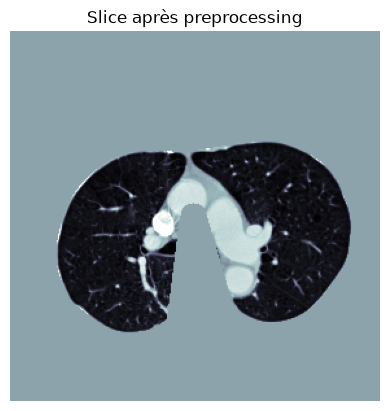

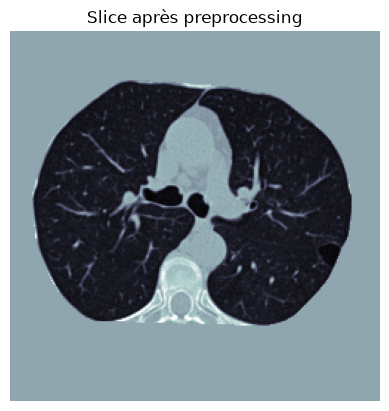

In [18]:
sample = np.load("../data/processed/train/1.3.6.1.4.1.14519.5.2.1.6279.6001.100621383016233746780170740405.npy")

plt.imshow(sample[200], cmap="bone")
plt.title("Slice après preprocessing")
plt.axis("off")
plt.show()

sample = np.load("../data/processed/train/1.3.6.1.4.1.14519.5.2.1.6279.6001.100684836163890911914061745866.npy")

plt.imshow(sample[200], cmap="bone")
plt.title("Slice après preprocessing")
plt.axis("off")
plt.show()


In [1]:
import os
import glob

def clean_directory(directory):
    if not os.path.exists(directory):
        print(f"⚠️  Dossier inexistant : {directory}")
        return

    files = glob.glob(os.path.join(directory, "*.npy"))
    for f in files:
        os.remove(f)
        print(f"🗑️  Supprimé : {f}")

    print(f"✅ Nettoyage terminé pour : {directory}")

# Nettoyage des dossiers processed
clean_directory("../data/processed/train")
clean_directory("../data/processed/val")
clean_directory("../data/processed/test")

# Nettoyage des métadonnées
clean_directory("../data/metadata/train")
clean_directory("../data/metadata/val")
clean_directory("../data/metadata/test")

🗑️  Supprimé : ../data/processed/train\1.3.6.1.4.1.14519.5.2.1.6279.6001.100621383016233746780170740405.npy
🗑️  Supprimé : ../data/processed/train\1.3.6.1.4.1.14519.5.2.1.6279.6001.100684836163890911914061745866.npy
🗑️  Supprimé : ../data/processed/train\1.3.6.1.4.1.14519.5.2.1.6279.6001.102133688497886810253331438797.npy
🗑️  Supprimé : ../data/processed/train\1.3.6.1.4.1.14519.5.2.1.6279.6001.104562737760173137525888934217.npy
🗑️  Supprimé : ../data/processed/train\1.3.6.1.4.1.14519.5.2.1.6279.6001.105756658031515062000744821260.npy
🗑️  Supprimé : ../data/processed/train\1.3.6.1.4.1.14519.5.2.1.6279.6001.106719103982792863757268101375.npy
🗑️  Supprimé : ../data/processed/train\1.3.6.1.4.1.14519.5.2.1.6279.6001.108197895896446896160048741492.npy
🗑️  Supprimé : ../data/processed/train\1.3.6.1.4.1.14519.5.2.1.6279.6001.108231420525711026834210228428.npy
🗑️  Supprimé : ../data/processed/train\1.3.6.1.4.1.14519.5.2.1.6279.6001.109002525524522225658609808059.npy
🗑️  Supprimé : ../data/proce